In [1]:
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import optuna
import joblib
from sklearn.model_selection import cross_val_score

In [2]:
sys.path.insert(0, str(Path.cwd().parent))

from src.data_loader import load_data

df_train, df_test = load_data()

To prevent data leakage from the test set to the train set, we avoid testing our baseline model on the final test set. 

Let us first try to find whether regularization coefficients have a substantial effect on the logisitic regression model.

To do so, we will perform a grid search.

In [3]:
from src.preprocessing import prepare_data, build_preprocessor

X_train, y_train = prepare_data(df_train)

preprocessor = build_preprocessor(X_train)

logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

param_grid = {"model__C": 
              [0.001, 0.01, 0.1, 1, 2, 5, 10, 15, 20, 25, 30, 35, 45, 50, 55]
              }
grid = GridSearchCV(logistic_pipeline, 
                    param_grid, 
                    scoring="accuracy", 
                    cv=5, 
                    return_train_score=True,
                    n_jobs=-1
                    )
grid.fit(X_train, y_train)

,estimator,Pipeline(step..._iter=2000))])
,param_grid,"{'model__C': [0.001, 0.01, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


In [4]:
print(f"The best score reached across these different values of C is {grid.best_score_}, with C={grid.best_params_["model__C"]}")

The best score reached across these different values of C is 0.7037856296058409, with C=45


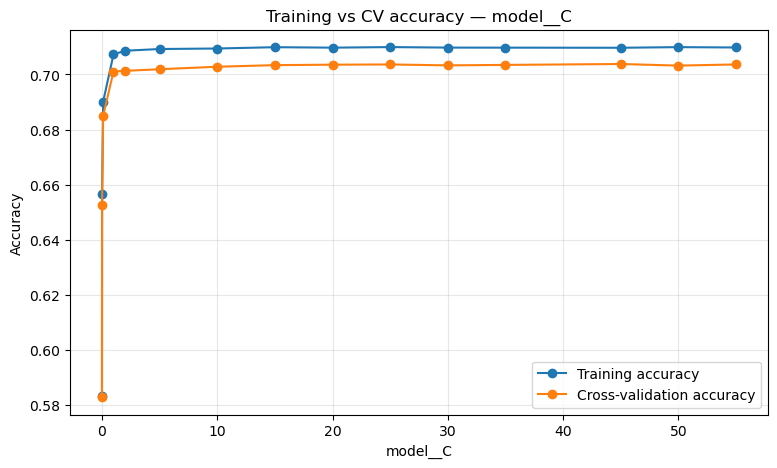

In [5]:
from src.vizualization import plot_hyperparam

plot_hyperparam(grid.cv_results_, param_name="model__C", fixed_params=None)

The higher C, the less L2 regularized are the coefficients. We see that here, regularization has very little impact on the performance of the model on the cross-validation set. Whatever the hyperparameter, performance remains still much lower than the one of a baseline non-linear model like a Decision Tree. We can thus suppose that this dataset probably contains non-linearities or interactions that a linear model cannot learn.  

To identify the optimal hyperparameters for our Decision Tree while limiting selection biais from repeatedly evaluating models on the test set, we perform a 5-fold cross-validation to evaluate model performance on unseen validation folds.

In [6]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(criterion='gini', random_state=42))
])

param_grid = {"model__max_depth": [1, 2, 5, 10, 15, 20, 25, 30, 40]}

grid = GridSearchCV(
    tree_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True,
    n_jobs=-1    
)

grid.fit(X_train, y_train)

print(f"The optimal maximum depth is {grid.best_params_['model__max_depth']}, with a mean cross-validation accuracy of {grid.best_score_}")



The optimal maximum depth is 15, with a mean cross-validation accuracy of 0.7751322348214378


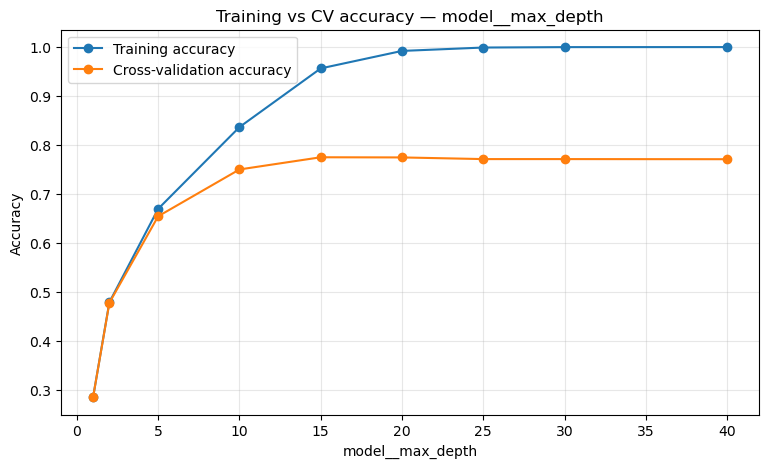

In [7]:
plot_hyperparam(grid.cv_results_, param_name="model__max_depth", fixed_params=None)

Among the maximum tree depths evaluated, a depth of 15 achieves the highest mean cross-validation accuracy, approximately 77.5%.

The curves show that validation accuracy initially increases with tree depth, before slightly decreasing and eventually stabilizing. Meanwhile, training accuracy continues to increase until it reaches 100%, suggesting that the tree becomes sufficiently flexible to memorize the training observations, potentially including noise.

Beyond a maximum depth of approximately 25, both training and validation accuracies plateau. This suggests that allowing additional depth no longer meaningfully changes the model's predictions, potentially because the trees have already reached their natural stopping conditions (leaf node impurity of 0).

These results illustrate the trade-off between model complexity and generalization: increasing tree depth improves the fit to the training data, but does not necessarily improve performance on unseen observations, or can even decrease it.

In [8]:
X_test, y_test = prepare_data(df_test)

y_test_pred = grid.best_estimator_.predict(X_test)

print(f"On the test set, the accuracy score reaches {accuracy_score(y_test, y_test_pred)}")

On the test set, the accuracy score reaches 0.781084656084656


In [9]:
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(criterion="gini", random_state=42))
])

param_grid = {"model__n_estimators": [10, 100, 200, 250, 300, 500]}

grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True,
    n_jobs=-1    
)

grid.fit(X_train, y_train)


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__n_estimators': [10, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


In [10]:
print(f"The optimal number of trees is {grid.best_params_['model__n_estimators']}, with a mean cross-validation accuracy of {grid.best_score_}")

The optimal number of trees is 200, with a mean cross-validation accuracy of 0.8565641153539986


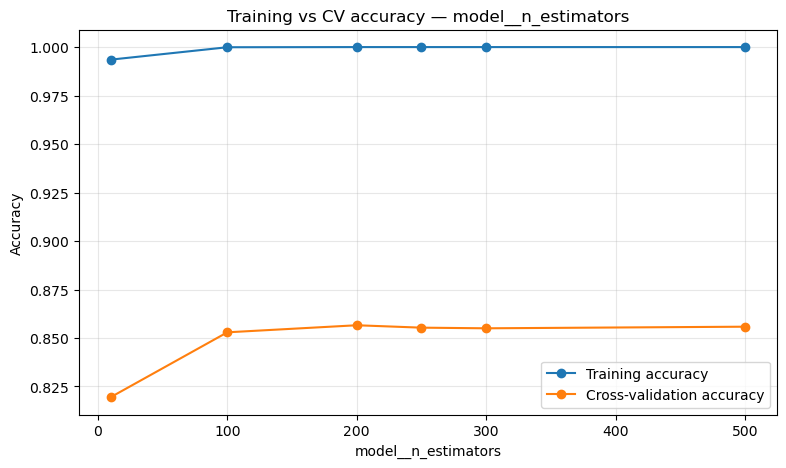

In [11]:
plot_hyperparam(grid.cv_results_, param_name="model__n_estimators", fixed_params=None)

The graph shows that increasing the number of trees initially improves cross-validation accuracy, as aggregating predictions helps reduce variance. Among the values tested, 200 trees achieve the highest cross-validation accuracy, although performance differences beyond this point are marginal.

By default, Random Forests impose no explicit maximum depth on individual trees. This allows them to capture complex relationships between features and the target variable, but also makes them susceptible to fitting sample-specific patterns.

Aggregating predictions helps mitigate this issue, as patterns specific to individual bootstrap samples tend to have less influence on the forest's overall predictions, while more generalizable relationships are more likely to be captured across multiple trees. However, the trees are not independent, as they come from the same dataset. Correlated errors between trees can limit the benefits of aggregation.

We will now fix the number of trees at 200 and investigate whether constraining their maximum depth improves cross-validation accuracy and reduces the generalization gap.

In [12]:
param_grid = {"model__max_depth" : [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]}
rf_pipeline.set_params(model__n_estimators=200)
grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True,
    n_jobs=-1    
)

grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [5, 10, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


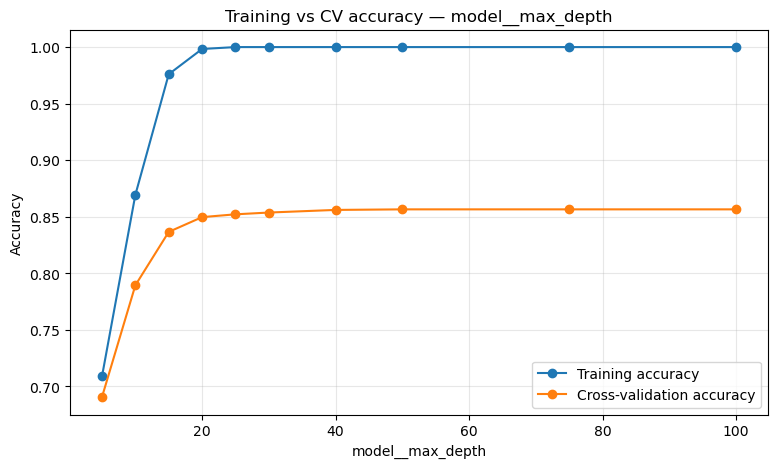

The best maximum depth is 50 with an accuracy score of 0.8565641153539986


In [13]:
plot_hyperparam(grid.cv_results_, "model__max_depth")
print(f"The best maximum depth is {grid.best_params_["model__max_depth"]} with an accuracy score of {grid.best_score_}")

We observe that increasing the maximum depth of individual trees initially improves the Random Forest's cross-validation accuracy.

Deeper trees can capture more complex relationships, reducing individual tree bias, while aggregation helps mitigate their variance. However, beyond a maximum depth of approximately 50, cross-validation accuracy plateaus, suggesting that further increasing tree complexity provides little additional predictive benefit.

This plateau may indicate that the trees have already captured most of the useful patterns available in the data. Remaining prediction errors may arise from correlated errors across trees that aggregation cannot fully eliminate.

In [14]:
param_grid = {"model__max_features":[0.1, 0.2, 0.4, 0.6, 0.8, 1.0]}
rf_pipeline.set_params(model__n_estimators=200, model__max_depth=50)

grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True,
    n_jobs=-1    
)

grid.fit(X_train, y_train)


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_features': [0.1, 0.2, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


In [15]:
print (f"The optimal proportion of max_features is {grid.best_params_["model__max_features"]}, with an cross-validation accuracy score of {grid.best_score_}")

The optimal proportion of max_features is 0.4, with an cross-validation accuracy score of 0.8602839094086416


In [16]:
y_test_pred=grid.predict(X_test)
print(f"On the test set, the accuracy score is {accuracy_score(y_test, y_test_pred)}")

On the test set, the accuracy score is 0.8624338624338624


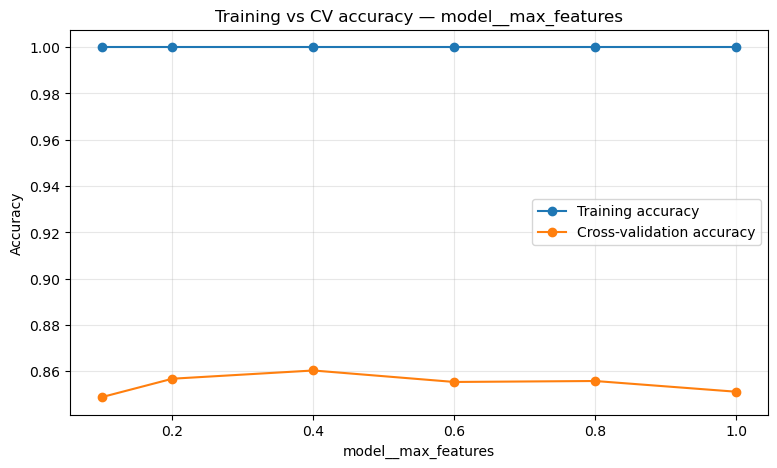

In [17]:
plot_hyperparam(grid.cv_results_, "model__max_features")

We observe a slight improvement in cross-validation accuracy when increasing `max_features` to 0.4.

With `max_features=0.4`, approximately 21 of the 54 features are randomly selected as candidates at each decision node. The algorithm then chooses the feature and split threshold that maximize impurity reduction among these candidates.

By default, `max_features="sqrt"`, meaning that approximately 7 features are considered at each node.

Increasing the number of candidate features gives individual trees a greater chance of selecting informative predictors, potentially improving their predictive performance.

Yet, when increasing this number of candidates too much, trees tend to select the same features, which increases the variance of the model. This trade-off could explain why cross-validation accuracy peaks around `max_features=0.4` before declining slightly at higher values.

These results suggest that an intermediate number of candidate features may provide a better balance between individual tree quality and ensemble diversity for this dataset.

In the previous experiments, we tuned the Random Forest hyperparameters sequentially. At each step, we optimized one hyperparameter using cross-validation, fixed its best-performing value, and moved on to the next. While this approach yielded strong results, it does not account for all possible interactions between hyperparameters and does not guarantee a globally optimal configuration.

To explore these interactions, we introduce Optuna, using its Tree-structured Parzen Estimator (TPE) sampler to adaptively search the hyperparameter space.

In [18]:
def objective(trial):

    n_estimators = trial.suggest_int("n_estimators", 100, 300)
    max_depth = trial.suggest_int("max_depth", 10, 50)
    max_features = trial.suggest_float("max_features", 0.1, 0.9)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 30)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 30)

    model = RandomForestClassifier(n_estimators=n_estimators,
                                   max_depth = max_depth,
                                   max_features = max_features,
                                   min_samples_split=min_samples_split,
                                   min_samples_leaf=min_samples_leaf)
    
    score = cross_val_score(model,X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)

    return score.mean()


In [19]:
random_path = Path.cwd().parent / "models" / "rf_optuna_random.joblib"

if random_path.exists():
    print("Loading existing study...")
    study = joblib.load(random_path)

else:
    print("Running new study...")
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(42))
    study.optimize(objective, n_trials=100)
    joblib.dump(study, random_path)

Loading existing study...


In [20]:
study.best_params

{'n_estimators': 200,
 'max_depth': 50,
 'max_features': 0.4,
 'min_samples_split': 2,
 'min_samples_leaf': 1}

In [21]:
study.best_value

0.8561504139064363

Interestingly, our initial Optuna search achieved a lower cross-validation accuracy than the sequential tuning approach. This illustrates that adaptive optimization does not necessarily outperform a targeted manual search, especially when the search space is large and the number of trials is limited.

In [22]:
best_rf = RandomForestClassifier(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train,y_train)

y_test_pred=best_rf.predict(X_test)

print(accuracy_score(y_test, y_test_pred))

0.8621031746031746


On test set too, the accuracy of the Optuna search is lower than the sequential tuning approach.

We therefore initialized a new Optuna study with our previously identified configuration using enqueue_trial(). By explicitly evaluating this promising configuration, we provided the TPE with additional information to guide subsequent trials.

In [23]:
best_path = Path.cwd().parent / "models" / "rf_optuna_best.joblib"

if best_path.exists():
    print("Loading existing study...")
    study_best = joblib.load(best_path)

else:
    print("Running new study...")

    study_best = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study_best.enqueue_trial({
    "n_estimators": 200,
    "max_depth": 50,
    "max_features": 0.4,
    "min_samples_split": 2,
    "min_samples_leaf": 1
    })
    
    study_best.optimize(objective, n_trials=100)

    joblib.dump(study_best, best_path)

Loading existing study...


In [25]:
study.best_params, study.best_value

({'n_estimators': 200,
  'max_depth': 50,
  'max_features': 0.4,
  'min_samples_split': 2,
  'min_samples_leaf': 1},
 0.8561504139064363)

In [26]:
best_rf = RandomForestClassifier(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train,y_train)

y_test_pred=best_rf.predict(X_test)

print(accuracy_score(y_test, y_test_pred))

0.8621031746031746


The resulting optimization achieved a slightly higher cross-validation and test accuracy than our previous approach, suggesting that combining prior experimental knowledge with adaptive hyperparameter search can be beneficial.

However, this improvement does not establish that the global optimum has been reached, nor that the initial configuration alone caused the improvement.

From now on, we will continue with another family of machine learning models, the Gradient Boosting models. The idea is not to push a little further the accuracy score of our models, but to try another machine learning approach and see whether it generalizes better than the models used so far.